Imports

In [4]:

!pip install -U scikit-learn

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    roc_auc_score
)



loading dataset

In [5]:
df = pd.read_csv('/content/sample_data/corporate_mail_access_requests_250k_balanced.csv')
print(df.shape)
df.info()

df.head()

(250000, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 22 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   request_id         250000 non-null  object 
 1   timestamp_day      250000 non-null  int64  
 2   sender_department  250000 non-null  object 
 3   sender_role        250000 non-null  object 
 4   sender_domain      250000 non-null  object 
 5   account_age_days   250000 non-null  int64  
 6   previous_requests  250000 non-null  int64  
 7   sender_reputation  250000 non-null  float64
 8   resource           250000 non-null  object 
 9   request_type       250000 non-null  object 
 10  manager_approval   250000 non-null  object 
 11  change_ticket      145548 non-null  object 
 12  project_code       162801 non-null  object 
 13  urgency            250000 non-null  object 
 14  recipient          250000 non-null  object 
 15  subject            250000 non-null  ob

,request_id,timestamp_day,sender_department,sender_role,sender_domain,account_age_days,previous_requests,sender_reputation,resource,request_type,...,project_code,urgency,recipient,subject,body,legacy_template,label,request_timestamp,mfa_verified,device_managed
0,REQ-0000001,1,Security,Security Analyst,corp.local,321,4,0.873,GitLab,build,...,PRJ-DELTA,normal,devops-access@corp.local,GitLab access request,"Hello Access Team,\n\nThis access is required ...",0,suspicious,2025-01-01 00:01:25,yes,yes
1,REQ-0000002,1,Product,Product Manager,corp.local,53,1,0.668,GitLab,write,...,NaN,high,devops-access@corp.local,Permission required for GitLab,"Hello Access Team,\n\nThe request is time sens...",0,suspicious,2025-01-01 00:04:06,no,no
2,REQ-0000003,1,HR,HR Executive,contractor.local,49,1,0.818,Jira,write,...,PRJ-BETA,high,it-access@corp.local,Jira access request,"Hello Access Team,\n\nPlease process this requ...",0,suspicious,2025-01-01 00:14:46,yes,no
3,REQ-0000004,1,QA,QA Engineer,corp.local,51,0,0.726,HRSystem,read,...,NaN,high,hr-systems@corp.local,Temporary HRSystem access request,"Hello Access Team,\n\nThe sender is requesting...",0,suspicious,2025-01-01 00:21:57,no,no
4,REQ-0000005,1,Sales,Sales Executive,contractor.local,59,0,0.785,Kubernetes,view,...,NaN,critical,platform-access@corp.local,Priority access request for Kubernetes,"Hello Access Team,\n\nAdditional verification ...",1,suspicious,2025-01-01 00:24:40,yes,yes


Feature Selection

In [6]:
TEXT_FEATURES = [
    "body",
    "subject"
]

CATEGORICAL_FEATURES = [
    "urgency",
    "sender_domain",
    "sender_reputation",
    "sender_role",
    "sender_department"
]

NUMERIC_FEATURES = [
    "account_age_days",
    "previous_requests"
]

Defining Input(x) and output(y) features


In [7]:
FEATURES = (
    TEXT_FEATURES
    + CATEGORICAL_FEATURES
    + NUMERIC_FEATURES
)

X = df[FEATURES].copy()

y = (df["label"] == "suspicious").astype(int)

Train test split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Body encoding / TF-IDF Vectorization

In [9]:
body_vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.98,
    sublinear_tf=True,
    max_features=60000
)

X_body_train = body_vectorizer.fit_transform(
    X_train["body"]
)

X_body_test = body_vectorizer.transform(
    X_test["body"]
)

Subject encoding / TF-IDF Vectorization

In [10]:

subject_vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.98,
    sublinear_tf=True,
    max_features=60000
)

X_subject_train = subject_vectorizer.fit_transform(
    X_train["subject"]
)

X_subject_test = subject_vectorizer.transform(
    X_test["subject"]
)

Features encoding (one hot encoding)

In [11]:
metadata_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_FEATURES
        ),
        (
            "numeric",
            StandardScaler(),
            NUMERIC_FEATURES
        )
    ]
)

Fit the metadata processor

In [12]:
X_meta_train = metadata_preprocessor.fit_transform(
    X_train
)

X_meta_test = metadata_preprocessor.transform(
    X_test
)

Feature weighting

In [13]:
#defining weight
BODY_WEIGHT = 1.0
SUBJECT_WEIGHT = 0.7
METADATA_WEIGHT = 1.5

X_train_combined = hstack([
    X_body_train * BODY_WEIGHT,
    X_subject_train * SUBJECT_WEIGHT,
    X_meta_train * METADATA_WEIGHT
]).tocsr()

Training the model


In [14]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
    solver="liblinear"
)

model.fit(
    X_train_combined,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0

test model

In [15]:
X_test_combined = hstack([
    X_body_test * BODY_WEIGHT,
    X_subject_test * SUBJECT_WEIGHT,
    X_meta_test * METADATA_WEIGHT
]).tocsr()

y_probability = model.predict_proba(
    X_test_combined
)[:, 1]

y_prediction = (
    y_probability >= 0.50
).astype(int)

Evaluate the model

In [16]:
print(
    classification_report(
        y_test,
        y_prediction,
        target_names=[
            "trusted",
            "suspicious"
        ]
    )
)

print(
    confusion_matrix(
        y_test,
        y_prediction
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        y_probability
    )
)

              precision    recall  f1-score   support

     trusted       0.90      0.95      0.93     25000
  suspicious       0.95      0.89      0.92     25000

    accuracy                           0.92     50000
   macro avg       0.93      0.92      0.92     50000
weighted avg       0.93      0.92      0.92     50000

[[23855  1145]
 [ 2633 22367]]
ROC-AUC: 0.96292996


confusion matrix

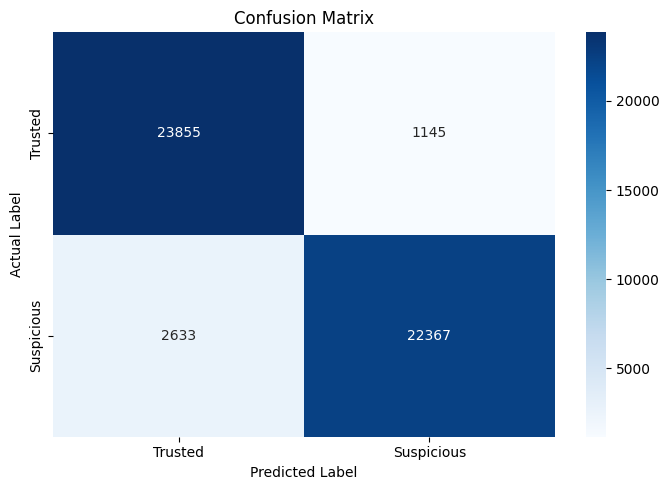

In [17]:
# Create confusion matrix
cm = confusion_matrix(y_test, y_prediction)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Trusted", "Suspicious"],
    yticklabels=["Trusted", "Suspicious"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

Save the model

In [18]:
joblib.dump(
    model,
    "model.pkl"
)

joblib.dump(
    body_vectorizer,
    "body_vectorizer.pkl"
)

joblib.dump(
    subject_vectorizer,
    "subject_vectorizer.pkl"
)

joblib.dump(
    metadata_preprocessor,
    "metadata_preprocessor.pkl"
)

['metadata_preprocessor.pkl']